# ChefBot - Entrega 1: Datos, aprendizaje supervisado y no supervisado

**Equipo:** Alvaro, Adan, Angel, Vencha

**Cómo usar este notebook (en Google Colab):**
1. Súbelo a Colab (Archivo > Subir cuaderno).
2. Ejecuta las celdas **en orden**, de arriba hacia abajo (Entorno de ejecución > Ejecutar todo).
3. La primera descarga tarda varios minutos (el archivo pesa ~5 GB). Es normal.
4. Cada sección indica quién es el responsable de explicarla en el informe.

| Sección | Responsable | Qué hace |
|---|---|---|
| 1. Datos | Alvaro | Descarga, exploración, preprocesamiento y división |
| 2. Características | Vencha | Convierte cada foto en números (color, textura, forma) |
| 3. Supervisado | Adan | Entrena 3 modelos y los evalúa |
| 4. No supervisado | Angel | PCA + GMM para agrupar platillos por apariencia |
| 5. Cierre | Todos | Resumen para el informe |

Todo el notebook usa la semilla `42` para que los resultados se puedan repetir.

In [ ]:
# ============================================================
# 0. CONFIGURACIÓN GENERAL (ejecutar siempre primero)
# ============================================================
import os, random, time, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# Semilla fija para que todo sea reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Las 10 clases del subconjunto de Food-101
CLASES = ["pizza", "hamburger", "sushi", "caesar_salad", "tacos",
          "ice_cream", "spaghetti_bolognese", "omelette",
          "chocolate_cake", "hot_and_sour_soup"]

IMG_SIZE = 128          # las imágenes se redimensionan a 128x128
DATA_DIR = Path("/content/data")
IMG_DIR = DATA_DIR / "food-101" / "images"

sns.set_theme(style="whitegrid")
print("Configuración lista.")

Configuración lista.


---
# 1. Datos  *(Responsable: Líder de proyecto y datos)*

**Dataset:** Food-101 (Bossard et al., 2014). Contiene 101 categorías de comida con 1,000 imágenes cada una.
Aquí se usa un subconjunto de **10 clases** (≈10,000 imágenes), tomadas de fotos reales de la web.

## 1.1 Descarga del dataset
Se descarga el archivo completo y se extraen **solo** las 10 carpetas que necesitamos.

In [ ]:
# Descargar Food-101 y extraer únicamente las 10 clases elegidas
if not IMG_DIR.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    archivo = "/content/food-101.tar.gz"
    url = "https://data.vision.ee.ethz.ch/cvl/food-101.tar.gz"

    print("Descargando Food-101 (~5 GB). Puede tardar varios minutos...")
    subprocess.run(["wget", "-q", "-c", url, "-O", archivo], check=True)

    print("Extrayendo solo las 10 clases...")
    rutas = [f"food-101/images/{c}" for c in CLASES]
    subprocess.run(["tar", "-xzf", archivo, "-C", str(DATA_DIR)] + rutas, check=True)

    os.remove(archivo)   # liberar espacio
    print("Listo.")
else:
    print("El dataset ya estaba descargado.")

Descargando Food-101 (~5 GB). Puede tardar varios minutos...
Extrayendo solo las 10 clases...
Listo.


## 1.2 Análisis exploratorio: cuántas imágenes hay por clase

Total de imágenes: 10000
Número de clases: 10

clase
pizza                  1000
hamburger              1000
sushi                  1000
caesar_salad           1000
tacos                  1000
ice_cream              1000
spaghetti_bolognese    1000
omelette               1000
chocolate_cake         1000
hot_and_sour_soup      1000
Name: count, dtype: int64


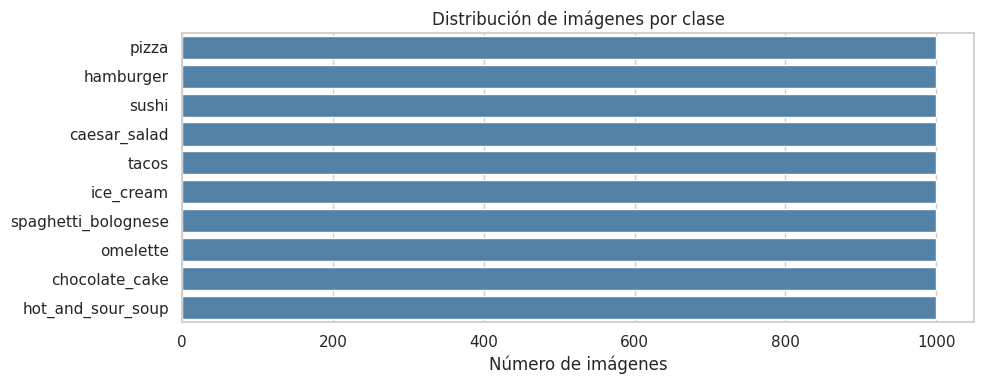

In [ ]:
# Armar una tabla con la ruta de cada imagen y su clase
registros = []
for c in CLASES:
    for p in sorted((IMG_DIR / c).glob("*.jpg")):
        registros.append((str(p), c))

df = pd.DataFrame(registros, columns=["ruta", "clase"])
print("Total de imágenes:", len(df))
print("Número de clases:", df["clase"].nunique())
print()
print(df["clase"].value_counts())

plt.figure(figsize=(10, 4))
sns.countplot(data=df, y="clase", order=CLASES, color="steelblue")
plt.title("Distribución de imágenes por clase")
plt.xlabel("Número de imágenes")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 1.3 Ejemplos visuales (una foto al azar por clase)

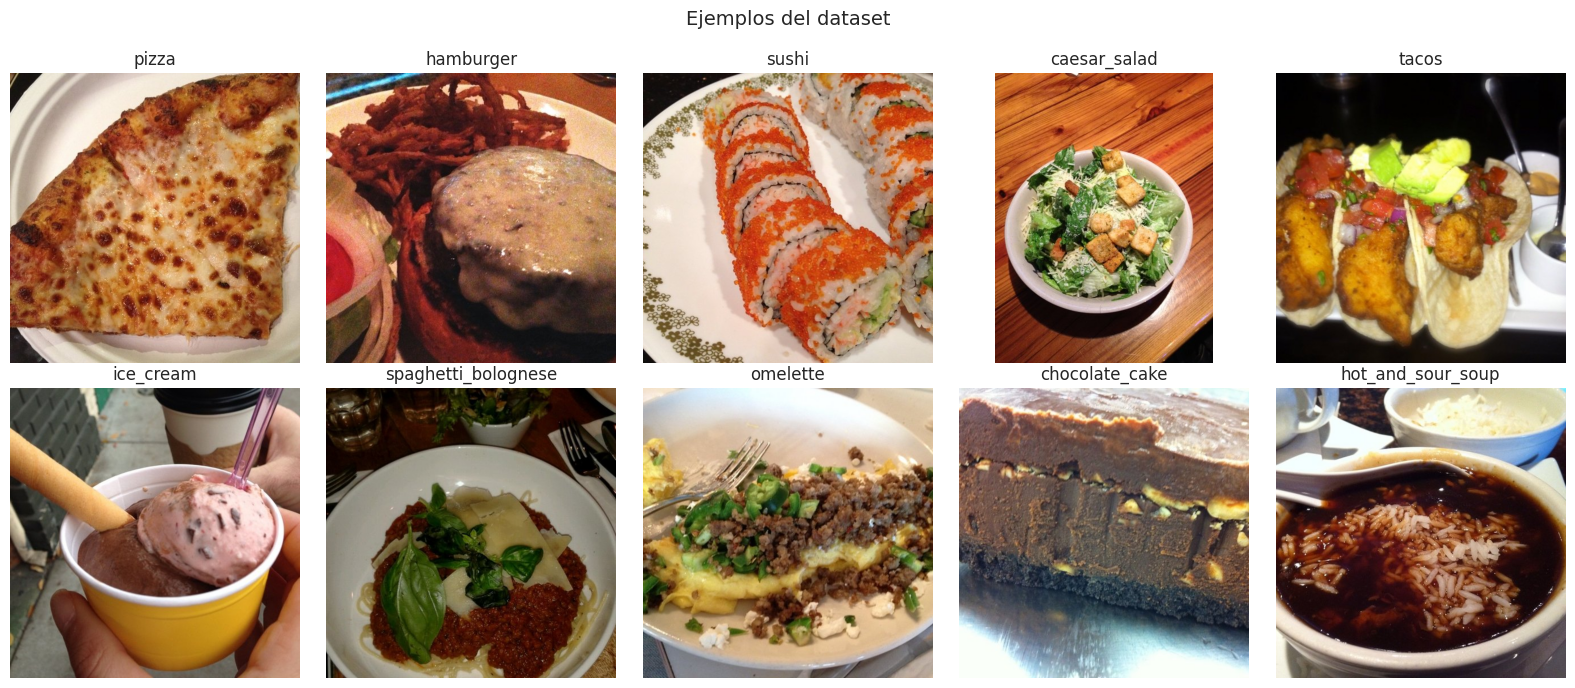

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, c in zip(axes.ravel(), CLASES):
    ruta = df[df.clase == c].sample(1, random_state=SEED).ruta.iloc[0]
    ax.imshow(Image.open(ruta))
    ax.set_title(c)
    ax.axis("off")
plt.suptitle("Ejemplos del dataset", fontsize=14)
plt.tight_layout()
plt.show()

## 1.4 Carga, redimensionado, tamaños originales y detección de imágenes dañadas
Se abre cada imagen, se convierte a RGB y se redimensiona a 128x128. Si alguna no se puede abrir, se descarta y se registra.

  0%|          | 0/10000 [00:00<?, ?it/s]

Imágenes cargadas correctamente: 10000
Imágenes dañadas: 0
Forma del arreglo de imágenes: (10000, 128, 128, 3)

         ancho     alto
count  10000.0  10000.0
mean     494.1    473.6
std       47.5     66.3
min      287.0    210.0
25%      512.0    384.0
50%      512.0    512.0
75%      512.0    512.0
max      512.0    512.0


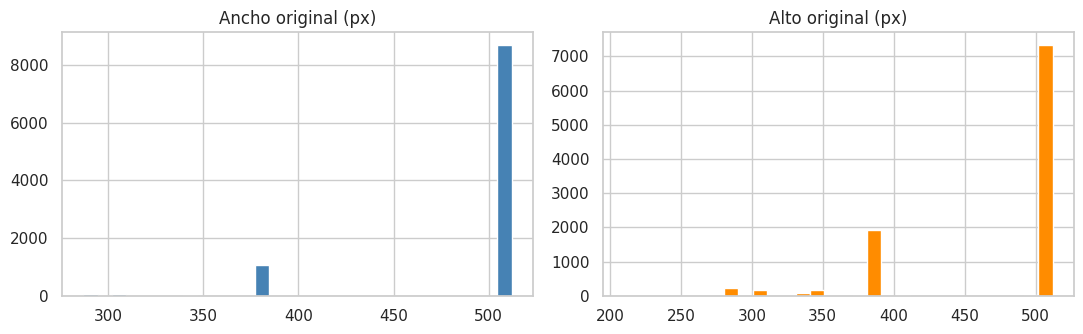


Clase con más imágenes: pizza (1000)
Clase con menos imágenes: pizza (1000)


In [ ]:
imagenes, clases_ok, tamanos, danadas = [], [], [], []

for ruta, clase in tqdm(zip(df.ruta, df.clase), total=len(df)):
    try:
        with Image.open(ruta) as im:
            im = im.convert("RGB")
            tamanos.append(im.size)                       # (ancho, alto) original
            im_red = im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            imagenes.append(np.asarray(im_red, dtype=np.uint8))
            clases_ok.append(clase)
    except Exception as e:
        danadas.append(ruta)                              # imagen dañada

X_img = np.stack(imagenes)            # (N, 128, 128, 3) con valores 0-255
y_nombres = np.array(clases_ok)

print("Imágenes cargadas correctamente:", X_img.shape[0])
print("Imágenes dañadas:", len(danadas))
print("Forma del arreglo de imágenes:", X_img.shape)

# Tamaños originales
df_tam = pd.DataFrame(tamanos, columns=["ancho", "alto"])
print()
print(df_tam.describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df_tam["ancho"], bins=30, color="steelblue")
ax[0].set_title("Ancho original (px)")
ax[1].hist(df_tam["alto"], bins=30, color="darkorange")
ax[1].set_title("Alto original (px)")
plt.tight_layout()
plt.show()

# Desbalance de clases
conteo = pd.Series(y_nombres).value_counts()
print(f"\nClase con más imágenes: {conteo.idxmax()} ({conteo.max()})")
print(f"Clase con menos imágenes: {conteo.idxmin()} ({conteo.min()})")

## 1.5 Codificación de etiquetas y división Entrenamiento / Validación / Prueba (70 / 15 / 15)
La división es **estratificada** (mantiene la misma proporción de cada clase en los tres conjuntos) y usa semilla fija.

*Sobre la normalización:* las imágenes se guardan como enteros 0-255. Para los modelos clásicos, las características
se normalizan después (histogramas con suma 1 y `StandardScaler`). Para la CNN (Entrega 2) se dividirán entre 255.

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder()
y = le.fit_transform(y_nombres)           # clase -> número (0 a 9)
nombres_clases = list(le.classes_)
print("Clases codificadas:", dict(zip(nombres_clases, range(len(nombres_clases)))))

# Trabajamos con índices para poder usar la misma división en todo el proyecto
idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEED)

print(f"\nEntrenamiento: {len(idx_train)} | Validación: {len(idx_val)} | Prueba: {len(idx_test)}")

# Verificar que las proporciones por clase se mantienen
prop = pd.DataFrame({
    "train": pd.Series(y[idx_train]).value_counts(normalize=True).sort_index(),
    "val": pd.Series(y[idx_val]).value_counts(normalize=True).sort_index(),
    "test": pd.Series(y[idx_test]).value_counts(normalize=True).sort_index(),
})
prop.index = nombres_clases
print("\nProporción de cada clase en cada conjunto:")
print(prop.round(3))

Clases codificadas: {np.str_('caesar_salad'): 0, np.str_('chocolate_cake'): 1, np.str_('hamburger'): 2, np.str_('hot_and_sour_soup'): 3, np.str_('ice_cream'): 4, np.str_('omelette'): 5, np.str_('pizza'): 6, np.str_('spaghetti_bolognese'): 7, np.str_('sushi'): 8, np.str_('tacos'): 9}

Entrenamiento: 7000 | Validación: 1500 | Prueba: 1500

Proporción de cada clase en cada conjunto:
                     train  val  test
caesar_salad           0.1  0.1   0.1
chocolate_cake         0.1  0.1   0.1
hamburger              0.1  0.1   0.1
hot_and_sour_soup      0.1  0.1   0.1
ice_cream              0.1  0.1   0.1
omelette               0.1  0.1   0.1
pizza                  0.1  0.1   0.1
spaghetti_bolognese    0.1  0.1   0.1
sushi                  0.1  0.1   0.1
tacos                  0.1  0.1   0.1


**Observaciones para el informe (Líder):** escribe aquí qué viste en el análisis exploratorio:
¿las clases están balanceadas? ¿hubo imágenes dañadas? ¿los tamaños originales eran muy distintos entre sí?

---
# 2. Extracción de características  *(Responsable: Vencha)*

Los modelos clásicos no "ven" imágenes, necesitan números. Se convierte cada foto en un vector con tres tipos de información:

| Característica | Qué describe | Tamaño |
|---|---|---|
| **Histograma HSV** | Qué colores predominan (tono, saturación, brillo) | 128 |
| **Textura GLCM** | Qué tan rugosa, uniforme o contrastada es la superficie | 40 |
| **HOG** | La forma y la orientación de los bordes | 1,764 |

In [ ]:
import cv2
from skimage.feature import graycomatrix, graycoprops, hog
from joblib import Parallel, delayed

def hist_hsv(img_rgb):
    # Histograma de color en espacio HSV: 8 bins de tono, 4 de saturación, 4 de brillo
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    h = cv2.calcHist([hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256])
    h = h.flatten()
    return h / (h.sum() + 1e-8)            # normalizado para que sume 1

def textura_glcm(img_rgb):
    # Matriz de co-ocurrencia de niveles de gris (GLCM) y 5 propiedades de textura
    gris = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    gris = (gris // 8).astype(np.uint8)    # reducir a 32 niveles de gris
    glcm = graycomatrix(gris, distances=[1, 3],
                        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=32, symmetric=True, normed=True)
    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]
    return np.concatenate([graycoprops(glcm, p).flatten() for p in props])

def descriptor_hog(img_rgb):
    # Histograma de gradientes orientados (HOG): captura formas y bordes
    gris = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return hog(gris, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), block_norm="L2-Hys")

def extraer_caracteristicas(img_rgb):
    # Vector final = color + textura + forma
    return np.concatenate([hist_hsv(img_rgb),
                           textura_glcm(img_rgb),
                           descriptor_hog(img_rgb)]).astype(np.float32)

# Prueba con una sola imagen para verificar los tamaños
v = extraer_caracteristicas(X_img[0])
print("Tamaño del vector de una imagen:", v.shape[0])
print("  - HSV :", hist_hsv(X_img[0]).shape[0])
print("  - GLCM:", textura_glcm(X_img[0]).shape[0])
print("  - HOG :", descriptor_hog(X_img[0]).shape[0])

Tamaño del vector de una imagen: 1932
  - HSV : 128
  - GLCM: 40
  - HOG : 1764


In [ ]:
# Extraer características de TODAS las imágenes (usa todos los núcleos disponibles)
t0 = time.time()
X_feat = np.array(Parallel(n_jobs=-1, batch_size=64)(
    delayed(extraer_caracteristicas)(im) for im in X_img))
print(f"Matriz de características: {X_feat.shape}  (imágenes x características)")
print(f"Tiempo: {time.time() - t0:.0f} segundos")

# Guardar por si se desconecta Colab (se puede descargar desde el panel de archivos)
np.savez_compressed("/content/features.npz", X=X_feat, y=y,
                    idx_train=idx_train, idx_val=idx_val, idx_test=idx_test,
                    clases=np.array(nombres_clases))
print("Características guardadas en /content/features.npz")

Matriz de características: (10000, 1932)  (imágenes x características)
Tiempo: 31 segundos
Características guardadas en /content/features.npz


In [ ]:
# Separar las características según la división 70/15/15
X_train, y_train = X_feat[idx_train], y[idx_train]
X_val,   y_val   = X_feat[idx_val],   y[idx_val]
X_test,  y_test  = X_feat[idx_test],  y[idx_test]
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

X_train: (7000, 1932) | X_val: (1500, 1932) | X_test: (1500, 1932)


**Observaciones para el informe (Vencha):** explica con tus palabras qué captura cada característica
(color, textura, forma) y por qué pueden ayudar a distinguir, por ejemplo, un helado de una sopa.
Aquí también va la tabla de "quién hizo qué" del informe.

---
# 3. Aprendizaje supervisado  *(Responsable: Adan)*

Se entrenan **3 algoritmos**: Regresión Logística, SVM (kernel RBF) y Random Forest.
Para cada uno se hace **validación cruzada estratificada de 3 pliegues** y **búsqueda de hiperparámetros con GridSearchCV**
sobre el conjunto de entrenamiento. Después se comparan en el conjunto de **validación** y el mejor se evalúa una sola vez en **prueba**.

> Esta celda es la más lenta del notebook (varios minutos). No la interrumpas.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# Cada modelo: (pipeline, malla de hiperparámetros a probar)
modelos = {
    "Regresión Logística": (
        Pipeline([("sc", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=300, random_state=SEED))]),
        {"clf__C": [0.001, 0.01, 0.1]}),
    "SVM (RBF)": (
        Pipeline([("sc", StandardScaler()),
                  ("clf", SVC(kernel="rbf", gamma="scale", random_state=SEED))]),
        {"clf__C": [1, 10]}),
    "Random Forest": (
        Pipeline([("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))]),
        {"clf__n_estimators": [200, 400]}),
}

mejores = {}      # aquí se guardan los modelos ya ajustados
for nombre, (pipe, malla) in modelos.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, malla, cv=skf, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    mejores[nombre] = gs

    i = gs.best_index_
    media = gs.cv_results_["mean_test_score"][i]
    desv = gs.cv_results_["std_test_score"][i]
    print(f"{nombre}")
    print(f"   Mejores hiperparámetros: {gs.best_params_}")
    print(f"   F1 en validación cruzada: {media:.3f} (+/- {desv:.3f})")
    print(f"   Tiempo: {time.time() - t0:.0f} s\n")

Regresión Logística
   Mejores hiperparámetros: {'clf__C': 0.001}
   F1 en validación cruzada: 0.428 (+/- 0.005)
   Tiempo: 33 s

SVM (RBF)
   Mejores hiperparámetros: {'clf__C': 10}
   F1 en validación cruzada: 0.459 (+/- 0.007)
   Tiempo: 365 s

Random Forest
   Mejores hiperparámetros: {'clf__n_estimators': 400}
   F1 en validación cruzada: 0.428 (+/- 0.005)
   Tiempo: 432 s



## 3.1 Comparación de los 3 modelos en el conjunto de validación

Resultados en VALIDACIÓN (promedio macro entre las 10 clases):


,CV F1 (train),Accuracy,Precisión,Recall,F1
Modelo,,,,,
Regresión Logística,0.428,0.433,0.431,0.433,0.431
SVM (RBF),0.459,0.483,0.485,0.483,0.483
Random Forest,0.428,0.459,0.444,0.459,0.444


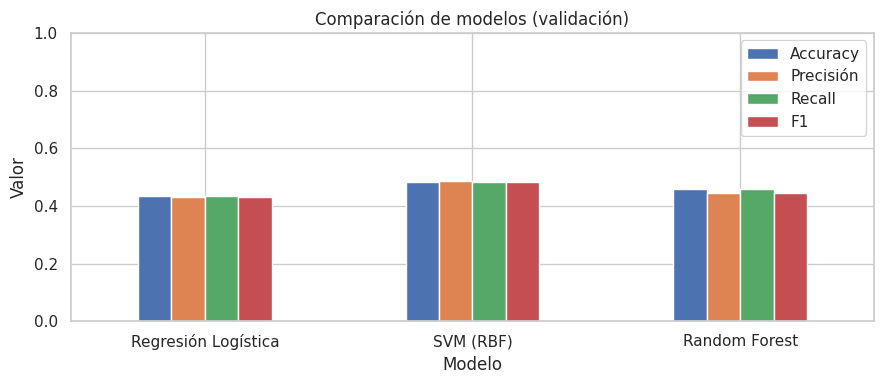


Mejor modelo según F1 en validación: SVM (RBF)


In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

filas = []
for nombre, gs in mejores.items():
    pred = gs.predict(X_val)
    p, r, f1, _ = precision_recall_fscore_support(y_val, pred, average="macro")
    filas.append({"Modelo": nombre,
                  "CV F1 (train)": gs.best_score_,
                  "Accuracy": accuracy_score(y_val, pred),
                  "Precisión": p, "Recall": r, "F1": f1})

tabla_val = pd.DataFrame(filas).set_index("Modelo").round(3)
print("Resultados en VALIDACIÓN (promedio macro entre las 10 clases):")
display(tabla_val)

tabla_val[["Accuracy", "Precisión", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4))
plt.title("Comparación de modelos (validación)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.ylabel("Valor")
plt.tight_layout()
plt.show()

mejor_nombre = tabla_val["F1"].idxmax()
print(f"\nMejor modelo según F1 en validación: {mejor_nombre}")

## 3.2 Evaluación final del mejor modelo en el conjunto de prueba

=== SVM (RBF) en PRUEBA ===
Accuracy: 0.467

                     precision    recall  f1-score   support

       caesar_salad      0.582     0.520     0.549       150
     chocolate_cake      0.545     0.607     0.574       150
          hamburger      0.364     0.373     0.368       150
  hot_and_sour_soup      0.706     0.720     0.713       150
          ice_cream      0.424     0.520     0.467       150
           omelette      0.333     0.280     0.304       150
              pizza      0.530     0.527     0.528       150
spaghetti_bolognese      0.555     0.473     0.511       150
              sushi      0.358     0.393     0.375       150
              tacos      0.271     0.253     0.262       150

           accuracy                          0.467      1500
          macro avg      0.467     0.467     0.465      1500
       weighted avg      0.467     0.467     0.465      1500



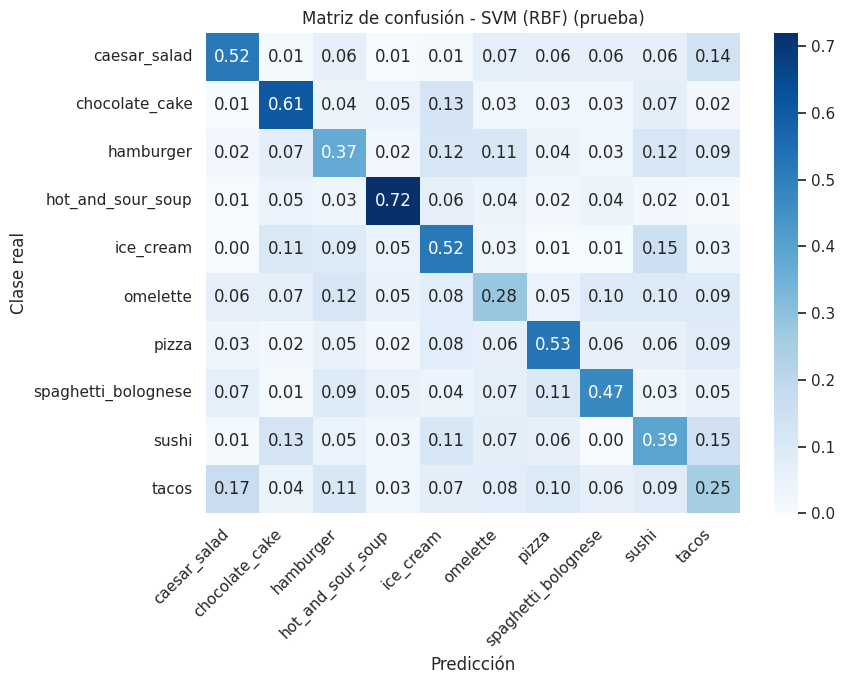

Los 5 errores más comunes (real -> predicho):
   tacos confundido con caesar_salad: 25 imágenes
   ice_cream confundido con sushi: 23 imágenes
   sushi confundido con tacos: 22 imágenes
   caesar_salad confundido con tacos: 21 imágenes
   sushi confundido con chocolate_cake: 19 imágenes


In [ ]:
mejor_modelo = mejores[mejor_nombre].best_estimator_
pred_test = mejor_modelo.predict(X_test)

print(f"=== {mejor_nombre} en PRUEBA ===")
print(f"Accuracy: {accuracy_score(y_test, pred_test):.3f}\n")
print(classification_report(y_test, pred_test, target_names=nombres_clases, digits=3))

# Matriz de confusión (normalizada por fila: qué fracción de cada clase real se predijo como cada clase)
cm = confusion_matrix(y_test, pred_test)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=nombres_clases, yticklabels=nombres_clases)
plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title(f"Matriz de confusión - {mejor_nombre} (prueba)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Errores más comunes
pares = []
for i in range(len(nombres_clases)):
    for j in range(len(nombres_clases)):
        if i != j and cm[i, j] > 0:
            pares.append((cm[i, j], nombres_clases[i], nombres_clases[j]))
pares.sort(reverse=True)

print("Los 5 errores más comunes (real -> predicho):")
for n, real, predicho in pares[:5]:
    print(f"   {real} confundido con {predicho}: {n} imágenes")

In [ ]:
# Tabla final de prueba para TODOS los modelos (útil para el informe)
filas = []
for nombre, gs in mejores.items():
    pred = gs.predict(X_test)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro")
    filas.append({"Modelo": nombre, "Accuracy": accuracy_score(y_test, pred),
                  "Precisión": p, "Recall": r, "F1": f1})
tabla_test = pd.DataFrame(filas).set_index("Modelo").round(3)
display(tabla_test)

,Accuracy,Precisión,Recall,F1
Modelo,,,,
Regresión Logística,0.437,0.432,0.437,0.432
SVM (RBF),0.467,0.467,0.467,0.465
Random Forest,0.454,0.444,0.454,0.439


**Observaciones para el informe (Adan):** ¿qué modelo ganó y por cuánto? ¿Qué platillos se confunden más y por qué
crees que pasa (colores parecidos, texturas parecidas)? ¿Qué hiperparámetros funcionaron mejor?

---
# 4. Aprendizaje no supervisado  *(Responsable: Angel)*

Aquí **no se usan las etiquetas para entrenar**. Se le pide a la computadora que agrupe las fotos solo por su apariencia:

1. **PCA:** reduce los ~1,900 números por imagen a unos pocos, conservando lo más importante.
2. **GMM (Gaussian Mixture Models):** agrupa las imágenes en grupos (clusters).
3. Al final se **comparan** los grupos con las clases reales, solo para interpretar los resultados.

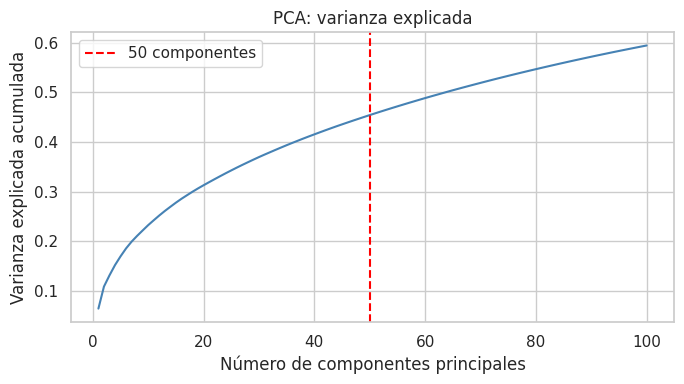

Con 50 componentes se conserva el 45.4% de la varianza.
Forma después de PCA: (10000, 50)


In [ ]:
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

# Normalizar todas las características (sin usar etiquetas)
X_all = StandardScaler().fit_transform(X_feat)

# ¿Cuántos componentes principales hacen falta? Mirar la varianza explicada acumulada
pca_full = PCA(n_components=100, random_state=SEED).fit(X_all)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 101), var_acum, color="steelblue")
plt.axvline(50, color="red", linestyle="--", label="50 componentes")
plt.xlabel("Número de componentes principales")
plt.ylabel("Varianza explicada acumulada")
plt.title("PCA: varianza explicada")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Con 50 componentes se conserva el {var_acum[49]*100:.1f}% de la varianza.")

# Reducir a 50 componentes para el agrupamiento
pca = PCA(n_components=50, random_state=SEED)
X_pca = pca.fit_transform(X_all)
print("Forma después de PCA:", X_pca.shape)

## 4.1 ¿Cuántos grupos? Criterio BIC
El BIC mide qué tan bien se ajusta el modelo penalizando la complejidad. **Menor BIC = mejor.**

  0%|          | 0/14 [00:00<?, ?it/s]

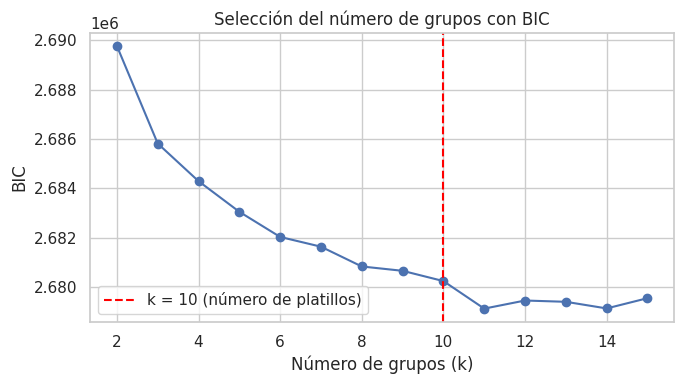

k con menor BIC: 11


In [ ]:
ks = range(2, 16)
bics = []
for k in tqdm(ks):
    g = GaussianMixture(n_components=k, covariance_type="diag", n_init=2, random_state=SEED)
    g.fit(X_pca)
    bics.append(g.bic(X_pca))

plt.figure(figsize=(7, 4))
plt.plot(list(ks), bics, marker="o")
plt.axvline(10, color="red", linestyle="--", label="k = 10 (número de platillos)")
plt.xlabel("Número de grupos (k)")
plt.ylabel("BIC")
plt.title("Selección del número de grupos con BIC")
plt.legend()
plt.tight_layout()
plt.show()
print("k con menor BIC:", list(ks)[int(np.argmin(bics))])

## 4.2 Agrupamiento con GMM (k = 10) y comparación con las clases reales

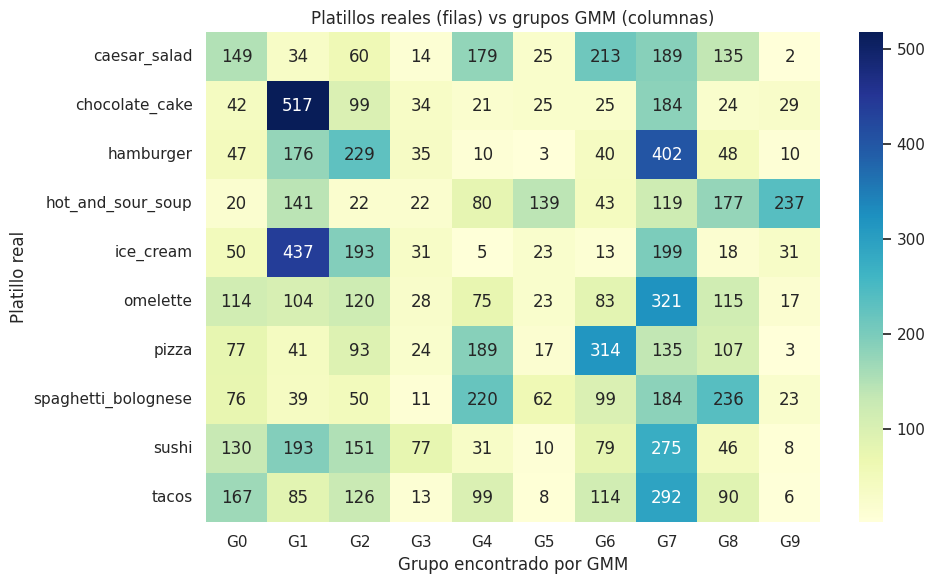

Pureza:                      0.254
Adjusted Rand Index (ARI):   0.060
Información mutua normalizada (NMI): 0.116

(Valores cercanos a 0 = los grupos casi no coinciden con los platillos; cercanos a 1 = coinciden mucho)


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

K = 10
gmm = GaussianMixture(n_components=K, covariance_type="diag", n_init=5, random_state=SEED)
gmm.fit(X_pca)
grupos_gmm = gmm.predict(X_pca)

# Tabla: cuántas fotos de cada platillo cayeron en cada grupo
tabla = pd.crosstab(y_nombres, grupos_gmm)
tabla.columns = [f"G{c}" for c in tabla.columns]

plt.figure(figsize=(10, 6))
sns.heatmap(tabla, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Platillos reales (filas) vs grupos GMM (columnas)")
plt.xlabel("Grupo encontrado por GMM")
plt.ylabel("Platillo real")
plt.tight_layout()
plt.show()

# Métricas de qué tanto coinciden los grupos con las clases
pureza = tabla.max(axis=0).sum() / tabla.values.sum()
print(f"Pureza:                      {pureza:.3f}")
print(f"Adjusted Rand Index (ARI):   {adjusted_rand_score(y, grupos_gmm):.3f}")
print(f"Información mutua normalizada (NMI): {normalized_mutual_info_score(y, grupos_gmm):.3f}")
print("\n(Valores cercanos a 0 = los grupos casi no coinciden con los platillos; cercanos a 1 = coinciden mucho)")

## 4.3 Visualización en 2D

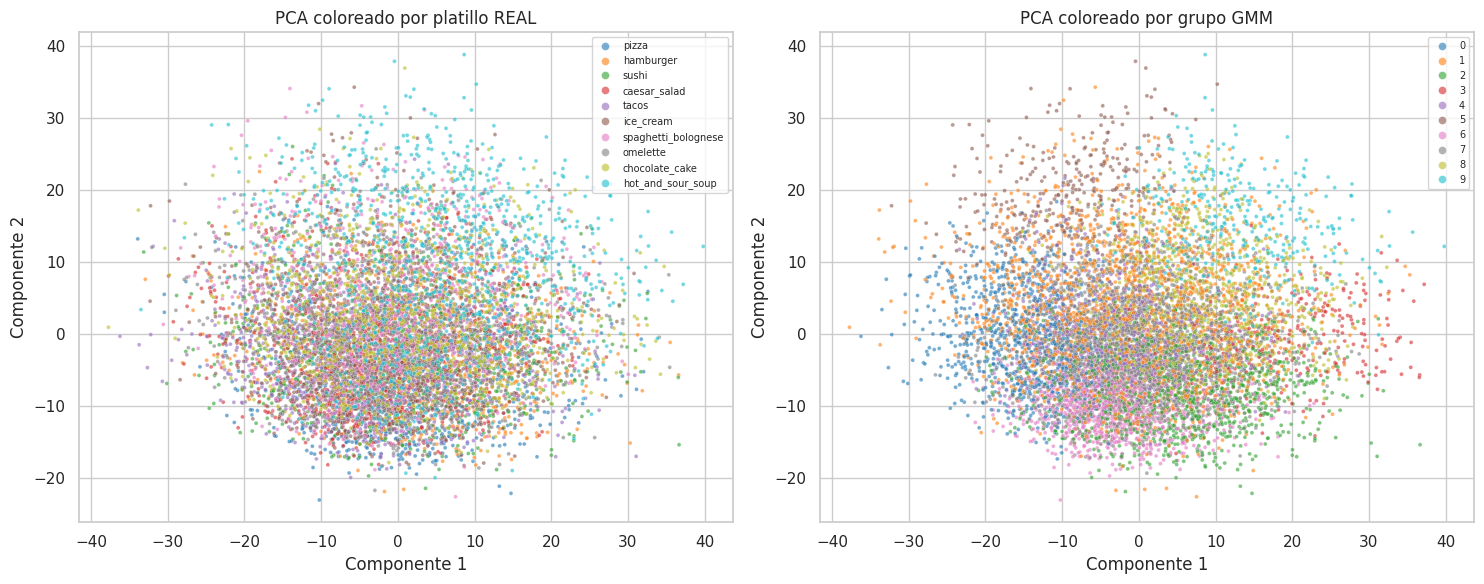

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_nombres, palette="tab10",
                s=8, alpha=0.6, ax=ax[0], legend="full")
ax[0].set_title("PCA coloreado por platillo REAL")
ax[0].legend(fontsize=7, markerscale=2)

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=grupos_gmm, palette="tab10",
                s=8, alpha=0.6, ax=ax[1], legend="full")
ax[1].set_title("PCA coloreado por grupo GMM")
ax[1].legend(fontsize=7, markerscale=2)

for a in ax:
    a.set_xlabel("Componente 1")
    a.set_ylabel("Componente 2")
plt.tight_layout()
plt.show()

## 4.4 ¿Qué platillos se parecen más? Propuesta de agrupación del menú
Se calcula el "centro" de cada platillo en el espacio PCA y se mide la distancia entre centros.
Platillos con centros cercanos se ven parecidos. Con un dendrograma se proponen grupos de menú por similitud visual.

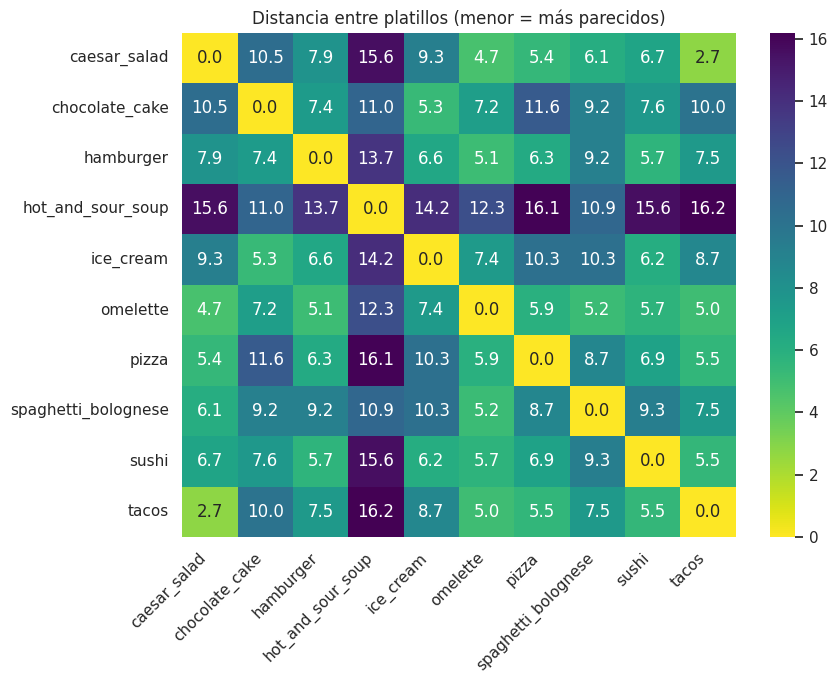

Los 5 pares de platillos más parecidos visualmente:
   caesar_salad y tacos (distancia 2.7)
   caesar_salad y omelette (distancia 4.7)
   omelette y tacos (distancia 5.0)
   hamburger y omelette (distancia 5.1)
   omelette y spaghetti_bolognese (distancia 5.2)


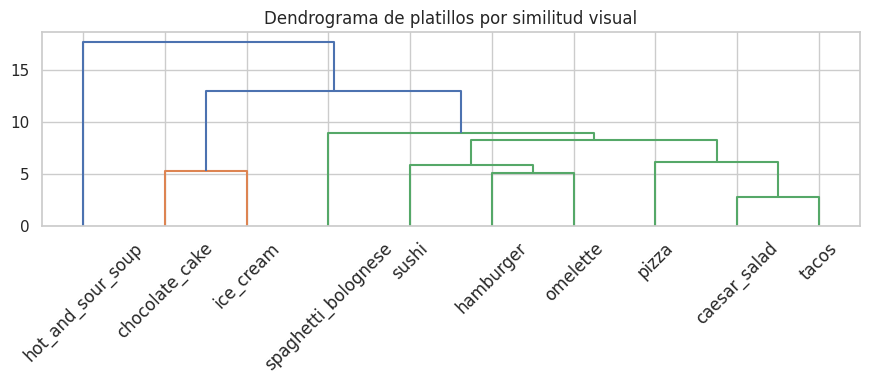


Propuesta de menú agrupado en 4 secciones por similitud visual:
   Sección 1: chocolate_cake, ice_cream
   Sección 2: caesar_salad, hamburger, omelette, pizza, sushi, tacos
   Sección 3: spaghetti_bolognese
   Sección 4: hot_and_sour_soup


In [ ]:
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Centro (promedio) de cada platillo en el espacio PCA
centroides = np.array([X_pca[y == k].mean(axis=0) for k in range(len(nombres_clases))])

# Matriz de distancias entre platillos
dist = cdist(centroides, centroides)
plt.figure(figsize=(9, 7))
sns.heatmap(pd.DataFrame(dist, index=nombres_clases, columns=nombres_clases),
            annot=True, fmt=".1f", cmap="viridis_r")
plt.title("Distancia entre platillos (menor = más parecidos)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Los 5 pares más parecidos
pares = []
for i in range(len(nombres_clases)):
    for j in range(i + 1, len(nombres_clases)):
        pares.append((dist[i, j], nombres_clases[i], nombres_clases[j]))
pares.sort()
print("Los 5 pares de platillos más parecidos visualmente:")
for d, a, b in pares[:5]:
    print(f"   {a} y {b} (distancia {d:.1f})")

# Dendrograma y propuesta de menú
Z = linkage(centroides, method="ward")
plt.figure(figsize=(9, 4))
dendrogram(Z, labels=nombres_clases, leaf_rotation=45)
plt.title("Dendrograma de platillos por similitud visual")
plt.tight_layout()
plt.show()

N_GRUPOS_MENU = 4
asignacion = fcluster(Z, t=N_GRUPOS_MENU, criterion="maxclust")
print(f"\nPropuesta de menú agrupado en {N_GRUPOS_MENU} secciones por similitud visual:")
for g in sorted(set(asignacion)):
    miembros = [n for n, a in zip(nombres_clases, asignacion) if a == g]
    print(f"   Sección {g}: {', '.join(miembros)}")

**Observaciones para el informe (Angel):** ¿los grupos de GMM coinciden con los platillos? (mira pureza, ARI y NMI).
¿Qué platillos se parecen más y por qué? ¿Tiene sentido la agrupación del menú que salió? Puedes probar
cambiar `N_GRUPOS_MENU` y comparar.

---
# 5. Cierre  *(Todos)*



In [ ]:
print("=== RESUMEN DE LA ENTREGA 1 ===")
print(f"Imágenes usadas: {len(y)} | Clases: {len(nombres_clases)}")
print(f"División: {len(idx_train)} train / {len(idx_val)} val / {len(idx_test)} test")
print(f"Características por imagen: {X_feat.shape[1]} (HSV 128 + GLCM 40 + HOG 1764)")
print(f"\nMejor modelo supervisado: {mejor_nombre}")
print("\nResultados en PRUEBA:")
display(tabla_test)
print(f"\nGMM (k={K}): pureza={pureza:.3f}")

=== RESUMEN DE LA ENTREGA 1 ===
Imágenes usadas: 10000 | Clases: 10
División: 7000 train / 1500 val / 1500 test
Características por imagen: 1932 (HSV 128 + GLCM 40 + HOG 1764)

Mejor modelo supervisado: SVM (RBF)

Resultados en PRUEBA:


,Accuracy,Precisión,Recall,F1
Modelo,,,,
Regresión Logística,0.437,0.432,0.437,0.432
SVM (RBF),0.467,0.467,0.467,0.465
Random Forest,0.454,0.444,0.454,0.439



GMM (k=10): pureza=0.254


### Checklist antes de entregar
- [ ] El notebook corre de principio a fin sin errores (Entorno de ejecución > Reiniciar y ejecutar todo).
- [ ] Guardado y subido a `notebooks/` del repositorio de GitHub.
- [ ] Informe de 4 a 6 páginas con las observaciones de cada sección y la tabla de tareas por integrante.
- [ ] Los 4 integrantes tienen al menos un commit.
- [ ] El README tiene los nombres del equipo completos.